## Recomendación: Contenido con búsqueda aproximada (HNSW)

- **Representación:** TF-IDF de la descripción de cada proceso + tokens de familia UNSPSC, reducida con SVD truncada

- **Proveedor** = promedio de los procesos en que **ofertó** en train (ganara o no); **entidad** = promedio de sus propios requerimientos en train

- **Actividad:** el puntaje se multiplica por $(\log(1 + \text{ofertas en train}))^{\gamma}$, para no recomendar oferentes ocasionales que solo se parecen en el texto

- **Búsqueda:** índice HNSW (`hnswlib`) sobre los proveedores, comparado con búsqueda exacta (fuerza bruta) en recall y tiempo

- Responde el lado de contenido de **PQ3.2**: a diferencia de ALS, puede recomendar a oferentes que **nunca ganaron**

### Constantes

- `MIN_DF`, `MAX_DF`, `MAX_FEAT`: vocabulario del TF-IDF (términos en ≥ 5 procesos, en ≤ 30%, hasta 50k)

- `RANGO_DIM`: dimensiones de la SVD que se comparan (y `"tfidf"`: el espacio completo, sin reducir)

- `RANGO_GAMMA`: exponente del factor de actividad del proveedor, $(\log(1 + \text{ofertas}))^{\gamma}$; γ = 0 es contenido puro

- `M_HNSW`, `EF_CONS`: conectividad del grafo HNSW y tamaño de la lista al construirlo

- `RANGO_PROF`: vecinos por coseno que se recuperan del índice antes de reordenar por actividad (`ef` = profundidad)

- `RECALL_MIN`: recall@200 mínimo frente a la búsqueda exacta para elegir la profundidad (el híbrido usa los 200 candidatos)

In [1]:
MIN_DF, MAX_DF, MAX_FEAT = 5, 0.30, 50_000
RANGO_DIM = [32, 64, 128, 256, 384, 512]
RANGO_GAMMA = [0, 0.5, 1, 2]
M_HNSW, EF_CONS = 16, 200
RANGO_PROF = [400, 1000, 2000]
RECALL_MIN = 0.95
STOP = ("de del la las el los y en a para por con al su sus que se un una o e u lo como mas sin sobre entre desde hasta "
        "segun ante bajo tras otro otros otra otras este esta estos estas ese esa dicho dicha anio periodo nro numero").split()

### Utilidades

In [2]:
NOTEBOOK = "c_contenido_ann"
%run ../funciones.ipynb
%run funciones.ipynb

/opt/conda/lib/python3.11/site-packages/nbformat/__init__.py:93: MissingIDFieldWarning: Code cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


In [4]:
import hnswlib, joblib
from IPython.display import Markdown, display
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize

ctx = {s: contexto(s) for s in SPLITS}

---
### **1. Documentos**

- **Proceso:** `doc_procesos` (`descripcion` + `items_desc` si difiere + tokens `fam<código>` de las familias UNSPSC)

- Solo procesos de los años de **train** de cada split: el vocabulario, el IDF y la SVD no ven el año de test

In [5]:
def documentos(s):
    an = SPLITS[s]["train"]
    pr = doc_procesos(leer(final_dir, "procesos").where(F.col("anio").isin(an)), an)
    part = (leer(final_dir, "participantes").where(F.col("anio").isin(an))
            .select("ocid", "proveedor_key").distinct().toPandas())
    return pr, part

docs = {s: documentos(s) for s in SPLITS}
for s, (pr, part) in docs.items():
    print(f"{s}: {len(pr):,} procesos, {pr.fams.notna().mean():.1%} con familia | {len(part):,} participaciones")
docs["final"][0][["doc"]].sample(3, random_state=SEED)

ajuste: 76,391 procesos, 66.0% con familia | 877,937 participaciones
final: 156,656 procesos, 66.5% con familia | 1,904,897 participaciones


,doc
142336,ADQUISICION DE COMBUSTIBLE DIESEL B5 S50 PARA LAS UNIDADES MOVILES DE LOS SE...
22052,Servicio de Consultoría para la Elaboración del Estudio a Nivel de Ficha Téc...
13216,"Adquisición de Diesel B5 S-50 para la flota de maquinaria pesada, vehicular ..."


---
### **2. TF-IDF y vectores de actores**

- `sublinear_tf`: 1 + log(tf), para que una palabra repetida no domine

- Proveedor: $v_i = \frac{1}{|P_i|}\sum_{p \in P_i} x_p$ (procesos en que participó) → norma L2

- Entidad: $v_u = \frac{1}{|P_u|}\sum_{p \in P_u} x_p$ (procesos que convocó) → norma L2

- Puntaje = coseno $v_u^\top v_i$: "el proveedor suele ofertar en procesos que se parecen a los que esta entidad convoca"

In [6]:
def promedio(filas, cols, shape, X):
    B = sparse.csr_matrix((np.ones(len(filas), dtype=np.float32), (filas, cols)), shape=shape)
    n = np.asarray(B.sum(1)).ravel(); n[n == 0] = 1
    return sparse.diags(1 / n) @ B @ X

esp = {}
for s, (pr, part) in docs.items():
    c = ctx[s]
    t0 = time.time()
    vec = TfidfVectorizer(strip_accents="unicode", lowercase=True, min_df=MIN_DF, max_df=MAX_DF, max_features=MAX_FEAT,
                          stop_words=STOP, token_pattern=r"(?u)\b[a-z][a-z0-9]{2,}\b", sublinear_tf=True, dtype=np.float32)
    X = vec.fit_transform(pr.doc)
    oc = pd.Series(np.arange(len(pr)), index=pr.ocid)
    prov = c.catalogo.proveedor_key.to_numpy(); pi = pd.Series(np.arange(len(prov)), index=prov)
    ents = c.key_e; ei = pd.Series(np.arange(len(ents)), index=ents)
    pa = part[part.proveedor_key.isin(pi.index) & part.ocid.isin(oc.index)]
    pe = pr[pr.entidad_key.isin(ei.index)]
    Vp = normalize(promedio(pi[pa.proveedor_key].to_numpy(), oc[pa.ocid].to_numpy(), (len(prov), len(pr)), X))
    Ve = normalize(promedio(ei[pe.entidad_key].to_numpy(), oc[pe.ocid].to_numpy(), (len(ents), len(pr)), X))
    act = np.log1p(pa.ocid.groupby(pa.proveedor_key).nunique().reindex(prov, fill_value=0).to_numpy()).astype(np.float32)
    esp[s] = dict(vec=vec, X=X, Vp=Vp, Ve=Ve, prov=prov, pi=pi, ents=ents, ei=ei, act=act)
    print(f"{s}: vocabulario {X.shape[1]:,} | proveedores sin texto {(np.asarray(Vp.sum(1)).ravel() == 0).mean():.2%} "
          f"| {time.time() - t0:.0f} s")

ajuste: vocabulario 12,959 | proveedores sin texto 0.00% | 2 s


final: vocabulario 19,627 | proveedores sin texto 0.00% | 5 s


#### a. Términos con más peso

Qué distingue a algunos proveedores grandes del catálogo

In [7]:
e = esp["final"]; voc = np.array(e["vec"].get_feature_names_out())
grandes = ctx["final"].catalogo.nlargest(5, "popularidad").proveedor_key
pd.DataFrame([{"proveedor_key": k, "terminos": ", ".join(voc[np.argsort(-e["Vp"][e["pi"][k]].toarray().ravel())[:8]])}
              for k in grandes])

,proveedor_key,terminos
0,RUC:20511037001,"cemento, portland, tipo, fam3011, acero, corrugado, puzolanico, mejoramiento"
1,RUC:20100028698,"fam2210, tractor, maquinaria, cargador, motoniveladora, frontal, excavadora,..."
2,RUC:20418896915,"seguro, fam8413, seguros, patrimoniales, personales, vida, poliza, ley"
3,RUC:20467534026,"internet, fam8312, telefonia, fam8311, movil, dedicado, datos, contratacion"
4,RUC:20100027021,"fam2210, retroexcavadora, camion, municipalidad, maquinaria, compactador, di..."


---
### **3. Reducción con SVD truncada**

- HNSW trabaja sobre vectores **densos**; el TF-IDF tiene decenas de miles de columnas dispersas

- La SVD se ajusta sobre los **procesos** de train y proyecta proveedores y entidades al mismo espacio

- Se elige la dimensión por NDCG@10 en pares nuevos del split **ajuste**, con búsqueda **exacta** (sin confundir el error del ANN con el de la reducción)

In [8]:
def rankear_vec(s, Q, D, excluir, n=N_CAND, lote=256):
    # top-n exacto de cada entidad evaluable sobre todo el catálogo de contenido
    c, e = ctx[s], esp[s]; filas = []
    q_idx = e["ei"][c.evaluables.entidad_key].to_numpy()
    for i in range(0, len(q_idx), lote):
        b = q_idx[i:i + lote]
        S = Q[b] @ D.T
        S = (S.toarray() if sparse.issparse(S) else np.asarray(S)).astype(np.float32)
        for j, u in enumerate(b):
            uk = e["ents"][u]
            if excluir and uk in c.vistos_key:
                S[j, e["pi"][[p for p in c.vistos_key[uk] if p in e["pi"].index]].to_numpy()] = -np.inf
            top = np.argpartition(-S[j], n - 1)[:n]; top = top[np.argsort(-S[j][top])]
            ok = np.isfinite(S[j][top]) & (S[j][top] > 0)
            filas.append(pd.DataFrame({"entidad_key": uk, "proveedor_key": e["prov"][top[ok]], "score": S[j][top[ok]],
                                       "rank": np.arange(1, ok.sum() + 1)}))
    return pd.concat(filas, ignore_index=True)

for s, e in esp.items():
    t0 = time.time()
    e["svd"] = TruncatedSVD(n_components=max(RANGO_DIM), algorithm="randomized", n_iter=5, random_state=SEED).fit(e["X"])
    e["Zp_full"], e["Ze_full"] = e["svd"].transform(e["Vp"]).astype(np.float32), e["svd"].transform(e["Ve"]).astype(np.float32)
    print(f"{s}: SVD {max(RANGO_DIM)} componentes en {time.time() - t0:.0f} s | "
          f"varianza explicada {e['svd'].explained_variance_ratio_.sum():.1%}")

def espacio(s, d, gamma=0):
    # proveedores escalados por actividad^gamma: el producto interno queda coseno × actividad^gamma
    e = esp[s]; a = e["act"] ** gamma
    if d == "tfidf":
        return e["Ve"], sparse.diags(a) @ e["Vp"]
    return normalize(e["Ze_full"][:, :d]), normalize(e["Zp_full"][:, :d]) * a[:, None]

ajuste: SVD 512 componentes en 8 s | varianza explicada 45.3%


final: SVD 512 componentes en 15 s | varianza explicada 43.3%


In [9]:
dims = []
for d in RANGO_DIM + ["tfidf"]:
    Q, D = espacio("ajuste", d); t0 = time.time()
    cand = {reg: rankear_vec("ajuste", Q, D, excluir=(reg == "nuevos"), n=50) for reg in ["todos", "nuevos"]}
    r = pd.DataFrame(evaluar_modelo(ctx["ajuste"], "contenido", cand))
    q = r[(r.grupo == "todas") & (r.k == 10)].set_index("regimen")
    dims.append({"dim": str(d), "ndcg10_nuevos": q.loc["nuevos", "ndcg"], "ndcg10_todos": q.loc["todos", "ndcg"],
                 "recall10_nuevos": q.loc["nuevos", "recall"], "pct_no_ganadores": q.loc["nuevos", "pct_no_ganadores"],
                 "seg": round(time.time() - t0, 1)})
dims = pd.DataFrame(dims)
dims.round(4)

,dim,ndcg10_nuevos,ndcg10_todos,recall10_nuevos,pct_no_ganadores,seg
0,32,0.0097,0.0248,0.0065,0.6612,7.0
1,64,0.0141,0.0359,0.0098,0.6670,7.2
2,128,0.0178,0.0453,0.0128,0.6820,7.4
3,256,0.0204,0.0533,0.0137,0.6981,7.6
4,384,0.0222,0.0579,0.0152,0.7090,7.9
5,512,0.0238,0.0607,0.0164,0.7212,8.1
6,tfidf,0.0284,0.0752,0.0227,0.7679,18.8


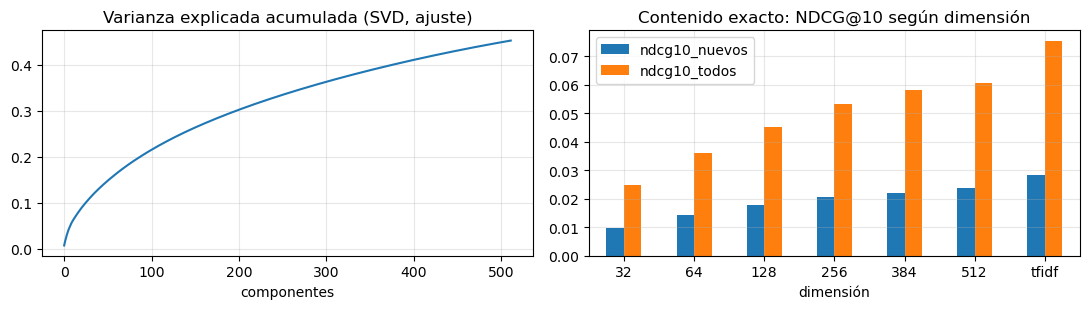

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(np.cumsum(esp["ajuste"]["svd"].explained_variance_ratio_), color="tab:blue")
ax[0].set(title="Varianza explicada acumulada (SVD, ajuste)", xlabel="componentes")
dims.plot.bar(x="dim", y=["ndcg10_nuevos", "ndcg10_todos"], ax=ax[1], rot=0)
ax[1].set(title="Contenido exacto: NDCG@10 según dimensión", xlabel="dimensión")
mostrar_fig("svd_dimension")

In [11]:
num = dims[dims.dim != "tfidf"].copy(); num["d"] = num.dim.astype(int)
DIM = int(num.sort_values(["ndcg10_nuevos", "d"], ascending=[False, True]).iloc[0].d)
full = dims.set_index("dim").loc["tfidf"]; sel = num.set_index("d").loc[DIM]
config = leer_config(); config["contenido"] = {"dim": DIM, "min_df": MIN_DF, "max_df": MAX_DF, "max_feat": MAX_FEAT}; guardar_config(config)
display(Markdown(
    f"- Mejor dimensión en nuevos: **{DIM}** (NDCG@10 {sel.ndcg10_nuevos:.3f}); TF-IDF completo: {full.ndcg10_nuevos:.3f}\n"
    f"- La reducción {'pierde' if sel.ndcg10_nuevos < full.ndcg10_nuevos else 'no pierde'} "
    f"{abs(full.ndcg10_nuevos - sel.ndcg10_nuevos):.3f} de NDCG frente al espacio completo, a cambio de vectores densos de {DIM} valores\n"
    f"- **{sel.pct_no_ganadores:.0%} de las recomendaciones** son oferentes que nunca ganaron (ALS: 0%)"
    + ("\n- ⚠ La mejor dimensión sigue en el borde de la grilla" if DIM == max(RANGO_DIM) else "")))

- Mejor dimensión en nuevos: **512** (NDCG@10 0.024); TF-IDF completo: 0.028
- La reducción pierde 0.005 de NDCG frente al espacio completo, a cambio de vectores densos de 512 valores
- **72% de las recomendaciones** son oferentes que nunca ganaron (ALS: 0%)
- ⚠ La mejor dimensión sigue en el borde de la grilla

#### a. Factor de actividad

$$s(u, i) = \cos(v_u, v_i) \cdot \big(\log(1 + o_i)\big)^{\gamma}$$

- $o_i$: procesos en que el proveedor **ofertó** en train (no usa adjudicaciones: un no ganador activo también sube)

- Se implementa escalando el vector de cada proveedor por $(\log(1 + o_i))^{\gamma}$: el producto interno con la entidad da exactamente $s(u, i)$, y HNSW con `space="ip"` lo busca sin cambios (búsqueda de máximo producto interno)

- γ se elige en el split ajuste, con búsqueda exacta y la dimensión ya elegida

In [12]:
gam = []
for g in RANGO_GAMMA:
    Q, D = espacio("ajuste", DIM, g)
    cand = {reg: rankear_vec("ajuste", Q, D, excluir=(reg == "nuevos"), n=50) for reg in ["todos", "nuevos"]}
    r = pd.DataFrame(evaluar_modelo(ctx["ajuste"], "contenido", cand))
    q = r[(r.grupo == "todas") & (r.k == 10)].set_index("regimen")
    gam.append({"gamma": g, "ndcg10_nuevos": q.loc["nuevos", "ndcg"], "ndcg10_todos": q.loc["todos", "ndcg"],
                "recall10_nuevos": q.loc["nuevos", "recall"], "pct_no_ganadores": q.loc["nuevos", "pct_no_ganadores"],
                "popularidad_media": q.loc["nuevos", "popularidad_media"], "cobertura": q.loc["nuevos", "cobertura"]})
gam = pd.DataFrame(gam)
gam.round(4)

,gamma,ndcg10_nuevos,ndcg10_todos,recall10_nuevos,pct_no_ganadores,popularidad_media,cobertura
0,0.0,0.0238,0.0607,0.0164,0.7212,0.8761,0.1619
1,0.5,0.0323,0.0667,0.0211,0.3823,4.8248,0.0514
2,1.0,0.0240,0.0468,0.0153,0.3386,5.5486,0.0229
3,2.0,0.0121,0.0250,0.0083,0.3564,5.2518,0.0083


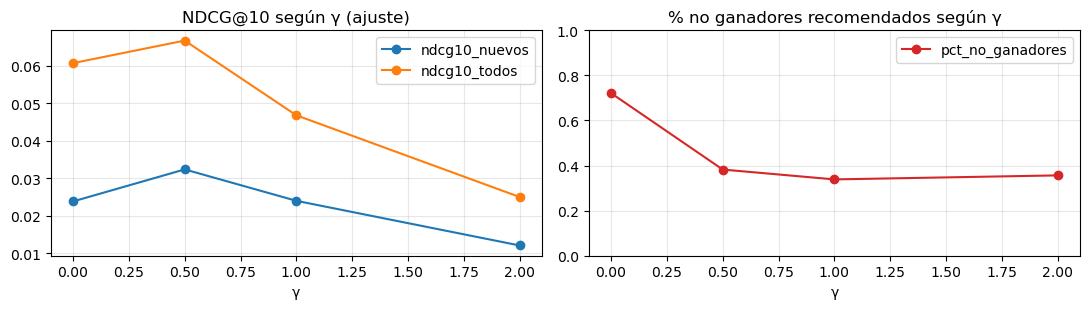

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
gam.plot(x="gamma", y=["ndcg10_nuevos", "ndcg10_todos"], marker="o", ax=ax[0])
ax[0].set(title="NDCG@10 según γ (ajuste)", xlabel="γ")
gam.plot(x="gamma", y="pct_no_ganadores", marker="o", ax=ax[1], color="tab:red")
ax[1].set(title="% no ganadores recomendados según γ", xlabel="γ", ylim=(0, 1))
mostrar_fig("contenido_gamma")

In [14]:
GAMMA = float(gam.sort_values(["ndcg10_nuevos", "gamma"], ascending=[False, True]).iloc[0].gamma)
g0, gs = gam.set_index("gamma").loc[0], gam.set_index("gamma").loc[GAMMA]
config = leer_config(); config["contenido"]["gamma"] = GAMMA; guardar_config(config)
display(Markdown(
    f"- Se elige **γ = {GAMMA:g}**: NDCG@10 nuevos {g0.ndcg10_nuevos:.3f} → **{gs.ndcg10_nuevos:.3f}** "
    f"(×{gs.ndcg10_nuevos / g0.ndcg10_nuevos:.1f} frente a contenido puro)\n"
    f"- Popularidad media de lo recomendado: {g0.popularidad_media:.1f} → {gs.popularidad_media:.1f} clientes; "
    f"% no ganadores: {g0.pct_no_ganadores:.0%} → **{gs.pct_no_ganadores:.0%}**\n"
    + ("- ⚠ γ quedó en el borde de la grilla\n" if GAMMA == max(RANGO_GAMMA) else "")
    + "- La actividad se mide en **ofertas**, no en adjudicaciones: un oferente frecuente que nunca ganó sigue siendo recomendable"))

- Se elige **γ = 0.5**: NDCG@10 nuevos 0.024 → **0.032** (×1.4 frente a contenido puro)
- Popularidad media de lo recomendado: 0.9 → 4.8 clientes; % no ganadores: 72% → **38%**
- La actividad se mide en **ofertas**, no en adjudicaciones: un oferente frecuente que nunca ganó sigue siendo recomendable

---
### **4. HNSW vs. búsqueda exacta**

- **HNSW** (*Hierarchical Navigable Small World*): grafo de vecinos en capas; la búsqueda baja de la capa más rala a la más densa saltando hacia vecinos más cercanos

- `M`: aristas por nodo; `ef_construction`: candidatos al construir; `ef`: candidatos al buscar (≥ k)

- **Recuperar y reordenar:** el índice se construye sobre vectores **normalizados** (coseno puro); se piden `PROF` vecinos por coseno y se reordenan por coseno × actividad^γ
    - Indexar los vectores ya escalados convierte la búsqueda en máximo producto interno, que no es una métrica: HNSW pierde vecinos lejanos (recall@200 ≈ 77% en la versión anterior)
    - El coseno sí se comporta como métrica en la esfera y HNSW lo aproxima bien; la actividad solo reordena

- Se mide sobre el split **final**: recall del proceso completo frente al top-k exacto de coseno × actividad, y tiempo por consulta

In [15]:
Qf, Df = espacio("final", DIM, 0)            # índice: coseno puro
act_g = esp["final"]["act"] ** GAMMA          # reordenamiento
t0 = time.time()
indice = hnswlib.Index(space="cosine", dim=DIM)
indice.init_index(max_elements=Df.shape[0], ef_construction=EF_CONS, M=M_HNSW, random_seed=SEED)
indice.add_items(Df, np.arange(Df.shape[0]), num_threads=4)
seg_build = time.time() - t0

e, c = esp["final"], ctx["final"]
q_idx = e["ei"][c.evaluables.entidad_key].to_numpy(); Qe = Qf[q_idx]
def top_exacto(Q, D, k, lote=256):
    out = []
    for i in range(0, len(Q), lote):
        S = Q[i:i + lote] @ D.T
        t = np.argpartition(-S, k - 1, axis=1)[:, :k]
        out.append(np.take_along_axis(t, np.argsort(-np.take_along_axis(S, t, 1), 1), 1))
    return np.vstack(out)

def recuperar_reordenar(idx, Q, prof, k, act):
    idx.set_ef(prof)
    lab, dist = idx.knn_query(Q, k=prof, num_threads=1)
    sc = (1 - dist) * act[lab]
    o = np.argsort(-sc, axis=1)[:, :k]
    return np.take_along_axis(lab, o, 1), np.take_along_axis(sc, o, 1)

t0 = time.time(); exacto = top_exacto(Qe, Df * act_g[:, None], N_CAND); seg_exacto = time.time() - t0

ann = []
for prof in RANGO_PROF:
    t0 = time.time(); lab, _ = recuperar_reordenar(indice, Qe, prof, N_CAND, act_g); seg = time.time() - t0
    rec = {k: np.mean([len(set(lab[j, :k]) & set(exacto[j, :k])) / k for j in range(len(Qe))]) for k in [10, N_CAND]}
    ann.append({"prof": prof, "recall10_vs_exacto": rec[10], f"recall{N_CAND}_vs_exacto": rec[N_CAND],
                "ms_por_consulta": 1000 * seg / len(Qe)})
ann = pd.DataFrame(ann)
ann["ms_exacto"] = 1000 * seg_exacto / len(Qe)
print(f"índice HNSW (coseno): {Df.shape[0]:,} proveedores × {DIM} dims, construido en {seg_build:.1f} s")
ann.round(4)

índice HNSW (coseno): 192,305 proveedores × 512 dims, construido en 18.4 s


,prof,recall10_vs_exacto,recall200_vs_exacto,ms_por_consulta,ms_exacto
0,400,0.8946,0.5297,0.5890,2.3725
1,1000,0.9762,0.8022,1.3502,2.3725
2,2000,0.9945,0.9487,2.7329,2.3725


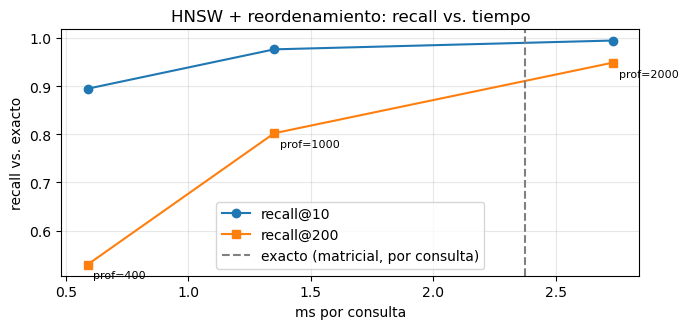

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(ann.ms_por_consulta, ann.recall10_vs_exacto, "o-", label="recall@10")
ax.plot(ann.ms_por_consulta, ann[f"recall{N_CAND}_vs_exacto"], "s-", label=f"recall@{N_CAND}")
for _, r in ann.iterrows():
    ax.annotate(f"prof={int(r.prof)}", (r.ms_por_consulta, r[f"recall{N_CAND}_vs_exacto"]), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.axvline(ann.ms_exacto.iloc[0], color="gray", ls="--", label="exacto (matricial, por consulta)")
ax.set(xlabel="ms por consulta", ylabel="recall vs. exacto", title="HNSW + reordenamiento: recall vs. tiempo"); ax.legend()
mostrar_fig("hnsw_recall_tiempo")

#### a. Escala

- Con ~200k proveedores la búsqueda exacta todavía es barata como producto matricial

- Se simula un catálogo mayor replicando los vectores con ruido, para ver cómo crece cada método (top-10 por coseno)

In [17]:
escala = []
rng = np.random.default_rng(SEED)
for mult in [1, 2, 4]:
    Dm = Df if mult == 1 else normalize(np.vstack([Df] + [Df + rng.normal(0, .05, Df.shape).astype(np.float32) for _ in range(mult - 1)]))
    idx_m = hnswlib.Index(space="cosine", dim=DIM); idx_m.init_index(max_elements=len(Dm), ef_construction=EF_CONS, M=M_HNSW, random_seed=SEED)
    t0 = time.time(); idx_m.add_items(Dm, num_threads=4); b = time.time() - t0
    idx_m.set_ef(200); t0 = time.time(); idx_m.knn_query(Qe[:200], k=10, num_threads=1); qa = (time.time() - t0) / 200
    t0 = time.time(); top_exacto(Qe[:200], Dm, 10, lote=50); qe = (time.time() - t0) / 200
    escala.append({"proveedores": len(Dm), "seg_construccion": b, "ms_hnsw": 1000 * qa, "ms_exacto": 1000 * qe})
    del idx_m, Dm
escala = pd.DataFrame(escala).round(3)
escala

,proveedores,seg_construccion,ms_hnsw,ms_exacto
0,192305,18.497,0.329,2.974
1,384610,38.688,0.381,5.764
2,769220,92.066,0.412,24.015


In [18]:
ok = ann[ann[f"recall{N_CAND}_vs_exacto"] >= RECALL_MIN]
PROF = int(ok.prof.min()) if len(ok) else int(ann.prof.max())
a = ann.set_index("prof").loc[PROF]
config = leer_config(); config["contenido"].update(prof=PROF, M=M_HNSW, ef_construction=EF_CONS, espacio_indice="cosine"); guardar_config(config)
crec = escala.set_index("proveedores")
display(Markdown(
    f"- Se elige **PROF = {PROF}**: menor profundidad con recall@{N_CAND} ≥ {RECALL_MIN:.0%} frente al exacto "
    f"({a[f'recall{N_CAND}_vs_exacto']:.1%}; recall@10 = {a.recall10_vs_exacto:.1%})"
    + ("" if len(ok) else f" — ⚠ ninguna profundidad llega a {RECALL_MIN:.0%}") + "\n"
    f"- Por consulta: HNSW + reordenamiento {a.ms_por_consulta:.2f} ms vs. exacto {a.ms_exacto:.2f} ms (exacto en lote, como producto matricial)\n"
    f"- Al multiplicar el catálogo ×{crec.index[-1] // crec.index[0]}, el exacto pasa de {crec.ms_exacto.iloc[0]:.2f} a {crec.ms_exacto.iloc[-1]:.2f} ms "
    f"(×{crec.ms_exacto.iloc[-1] / crec.ms_exacto.iloc[0]:.1f}) y HNSW de {crec.ms_hnsw.iloc[0]:.2f} a {crec.ms_hnsw.iloc[-1]:.2f} ms "
    f"(×{crec.ms_hnsw.iloc[-1] / crec.ms_hnsw.iloc[0]:.1f}): el exacto crece lineal con el catálogo y HNSW casi logarítmico"))

- Se elige **PROF = 2000**: menor profundidad con recall@200 ≥ 95% frente al exacto (94.9%; recall@10 = 99.4%) — ⚠ ninguna profundidad llega a 95%
- Por consulta: HNSW + reordenamiento 2.73 ms vs. exacto 2.37 ms (exacto en lote, como producto matricial)
- Al multiplicar el catálogo ×4, el exacto pasa de 2.97 a 24.02 ms (×8.1) y HNSW de 0.33 a 0.41 ms (×1.3): el exacto crece lineal con el catálogo y HNSW casi logarítmico

---
### **5. Candidatos con HNSW**

- Índice de coseno por split (ajuste y final): el híbrido calibra `w` en ajuste

- Por entidad se piden `PROF` + n.º de proveedores ya vistos, se reordenan por coseno × actividad^γ y:
    - **todos:** top-`N_CAND`
    - **nuevos:** top-`N_CAND` sin los vistos (HNSW no permite excluir en la búsqueda)

In [19]:
def candidatos_hnsw(s, d, prof):
    e, c = esp[s], ctx[s]
    Q, D = espacio(s, d, 0); act = e["act"] ** GAMMA
    idx = hnswlib.Index(space="cosine", dim=d); idx.init_index(max_elements=D.shape[0], ef_construction=EF_CONS, M=M_HNSW, random_seed=SEED)
    idx.add_items(D, np.arange(D.shape[0]), num_threads=4)
    out = {"todos": [], "nuevos": []}
    for uk in c.evaluables.entidad_key:
        vistos = c.vistos_key.get(uk, set())
        k = min(prof + len(vistos), D.shape[0])
        lab, sc = recuperar_reordenar(idx, Q[e["ei"][uk]][None, :], k, k, act)
        p, sc = e["prov"][lab[0]], sc[0]
        for reg, m in [("todos", np.ones(len(p), bool)), ("nuevos", ~np.isin(p, list(vistos)))]:
            pp, ss = p[m][:N_CAND], sc[m][:N_CAND]
            out[reg].append(pd.DataFrame({"entidad_key": uk, "proveedor_key": pp, "score": ss, "rank": np.arange(1, len(pp) + 1)}))
    return {reg: pd.concat(v, ignore_index=True) for reg, v in out.items()}

cand_cb = {s: candidatos_hnsw(s, DIM, PROF) for s in SPLITS}

---
### **6. Evaluación en el hold-out 2025**

Contenido (HNSW) frente a ALS y las líneas base de `b_baseline_als`, con los mismos candidatos guardados

In [20]:
c = ctx["final"]
cands = {m: leer_cand("final", m) for m in ["popularidad_global", "popularidad_familia", "als"]} | {"contenido": cand_cb["final"]}
res = []
for m, cd in cands.items():
    res += evaluar_modelo(c, m, cd, universos=("completo", "alcanzable"), conocidos=c.catalogo_keys)
res = pd.DataFrame(res)
cols = ["modelo", "precision", "recall", "ndcg", "map", "cobertura", "pct_cola_larga", "pct_no_ganadores", "popularidad_media"]
for reg in ["nuevos", "todos"]:
    print(f"régimen {reg}, K = 10")
    display(res[(res.regimen == reg) & (res.grupo == "todas") & (res.universo == "completo") & (res.k == 10)][cols].round(4))

régimen nuevos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
1,popularidad_global,0.0127,0.0116,0.0171,0.0072,0.0001,0.0000,0.0000,126.8135
17,popularidad_familia,0.0186,0.0137,0.0249,0.0107,0.0085,0.0191,0.0000,42.3981
33,als,0.0388,0.0392,0.0560,0.0256,0.0197,0.0224,0.0000,26.1336
57,contenido,0.0162,0.0129,0.0197,0.0077,0.0298,0.1860,0.2958,5.7729


régimen todos, K = 10


,modelo,precision,recall,ndcg,map,cobertura,pct_cola_larga,pct_no_ganadores,popularidad_media
9,popularidad_global,0.0287,0.0160,0.0369,0.0156,0.0001,0.0000,0.0000,130.0000
25,popularidad_familia,0.0543,0.0320,0.0721,0.0360,0.0077,0.0190,0.0000,46.9996
41,als,0.1558,0.1232,0.2141,0.1218,0.0244,0.0471,0.0000,27.0874
49,contenido,0.0443,0.0315,0.0561,0.0272,0.0305,0.1909,0.2602,6.5663


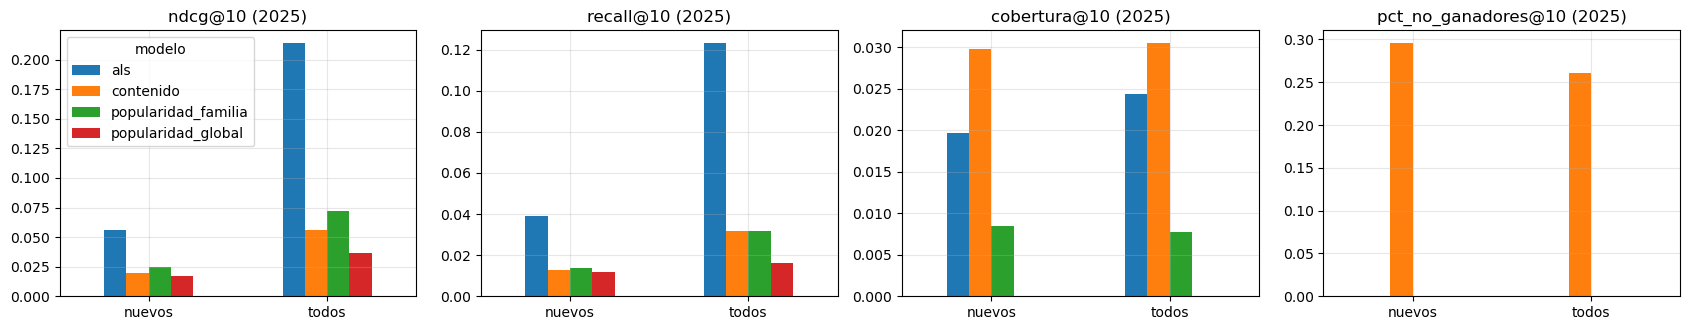

In [21]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.4))
q = res[(res.grupo == "todas") & (res.universo == "completo") & (res.k == 10)]
for i, met in enumerate(["ndcg", "recall", "cobertura", "pct_no_ganadores"]):
    q.pivot(index="regimen", columns="modelo", values=met).plot.bar(ax=ax[i], rot=0, legend=(i == 0))
    ax[i].set(title=f"{met}@10 (2025)", xlabel="")
mostrar_fig("final_comparacion_contenido")

#### a. Qué aciertos aporta cada modelo

- Aciertos en pares nuevos (top-10) según el proveedor acertado: ganador en train o **nunca ganó**

- Y cuántos aciertos de contenido **no** encuentra ALS: lo que el híbrido puede sumar

In [22]:
def aciertos(cd, k=10):
    r = a_recs(cd["nuevos"]); out = set()
    for u, rel in c.verdad["nuevos"].items():
        out |= {(u, p) for p in r.get(u, [])[:k] if p in rel}
    return out

h_als, h_cb = aciertos(cands["als"]), aciertos(cands["contenido"])
apor = pd.DataFrame([{"modelo": n, "aciertos": len(h), "a_no_ganadores": sum(p in c.no_ganadores for _, p in h),
                      "exclusivos": len(h - o)} for n, h, o in [("als", h_als, h_cb), ("contenido", h_cb, h_als)]])
apor["pct_no_ganadores"] = (apor.a_no_ganadores / apor.aciertos).round(3)
apor

,modelo,aciertos,a_no_ganadores,exclusivos,pct_no_ganadores
0,als,1013,0,921,0.000
1,contenido,423,77,331,0.182


In [23]:
v_cb = por_entidad(a_recs(cands["contenido"]["nuevos"]), c.verdad["nuevos"], 10)
v_als = por_entidad(a_recs(cands["als"]["nuevos"]), c.verdad["nuevos"], 10)
dif = ic_bootstrap(v_cb, v_als)
q = q.set_index(["regimen", "modelo"]); ap = apor.set_index("modelo")
t = res[(res.grupo == "todas") & (res.k == 10) & (res.regimen == "nuevos")].pivot_table(index="modelo", columns="universo", values="recall")
display(Markdown(
    f"- **Nuevos:** contenido NDCG@10 = {q.loc[('nuevos', 'contenido'), 'ndcg']:.3f} vs. ALS {q.loc[('nuevos', 'als'), 'ndcg']:.3f}; "
    f"diferencia {dif[0]:+.3f}, IC 95% [{dif[1]:+.3f}, {dif[2]:+.3f}]"
    + (" → contenido **mejor**" if dif[1] > 0 else " → ALS **mejor**" if dif[2] < 0 else " → **sin diferencia significativa**") + "\n"
    f"- **Todos:** contenido {q.loc[('todos', 'contenido'), 'ndcg']:.3f} vs. ALS {q.loc[('todos', 'als'), 'ndcg']:.3f}: "
    "el colaborativo aprovecha mejor la repetición de relaciones existentes\n"
    f"- **Diversidad:** cobertura {q.loc[('nuevos', 'contenido'), 'cobertura']:.2%} (ALS {q.loc[('nuevos', 'als'), 'cobertura']:.2%}); "
    f"popularidad media {q.loc[('nuevos', 'contenido'), 'popularidad_media']:.1f} clientes (ALS {q.loc[('nuevos', 'als'), 'popularidad_media']:.1f}); "
    f"**{q.loc[('nuevos', 'contenido'), 'pct_no_ganadores']:.0%} no ganadores** (ALS 0%)\n"
    f"- **Aciertos:** de {ap.loc['contenido', 'aciertos']:,} aciertos de contenido en pares nuevos, "
    f"**{ap.loc['contenido', 'a_no_ganadores']:,} ({ap.loc['contenido', 'pct_no_ganadores']:.0%}) son oferentes que nunca ganaron** "
    f"y {ap.loc['contenido', 'exclusivos']:,} no los encuentra ALS; ALS tiene {ap.loc['als', 'exclusivos']:,} exclusivos\n"
    f"- Los dos modelos aciertan en **conjuntos distintos**: es la condición para que el híbrido sume\n"
    f"- Recall sobre lo alcanzable por contenido: {t.loc['contenido', 'alcanzable']:.1%} vs. {t.loc['contenido', 'completo']:.1%} del total"))

- **Nuevos:** contenido NDCG@10 = 0.020 vs. ALS 0.056; diferencia -0.036, IC 95% [-0.041, -0.032] → ALS **mejor**
- **Todos:** contenido 0.056 vs. ALS 0.214: el colaborativo aprovecha mejor la repetición de relaciones existentes
- **Diversidad:** cobertura 2.98% (ALS 1.97%); popularidad media 5.8 clientes (ALS 26.1); **30% no ganadores** (ALS 0%)
- **Aciertos:** de 423 aciertos de contenido en pares nuevos, **77 (18%) son oferentes que nunca ganaron** y 331 no los encuentra ALS; ALS tiene 921 exclusivos
- Los dos modelos aciertan en **conjuntos distintos**: es la condición para que el híbrido sume
- Recall sobre lo alcanzable por contenido: 2.8% vs. 1.3% del total

#### b. Entidades cautivas (PQ3.1)

In [24]:
caut = res[(res.regimen == "nuevos") & (res.universo == "completo") & (res.k == 10)].pivot_table(
    index="modelo", columns="grupo", values=["ndcg", "recall", "pct_no_ganadores"]).round(4)
caut

ndcg         pct_no_ganadores           recall        
grupo               cautivas   todas         cautivas   todas cautivas   todas
modelo                                                                        
als                   0.0419  0.0560           0.0000  0.0000   0.0418  0.0392
contenido             0.0108  0.0197           0.2958  0.2958   0.0124  0.0129
popularidad_familia   0.0128  0.0249           0.0000  0.0000   0.0120  0.0137
popularidad_global    0.0138  0.0171           0.0000  0.0000   0.0145  0.0116

---
### **7. Escritura de datos**

- `temp/datos/<split>_cand_contenido`: top-`N_CAND` de HNSW por entidad y régimen (entrada del híbrido)

- `temp/datos/<split>_contenido_{proveedor,entidad}`: vectores SVD normalizados; los de proveedor ya escalados por actividad^γ (el híbrido puntúa con ellos los candidatos de ALS que HNSW no trajo)

- `temp/datos/<split>_contenido_modelo.joblib`: vectorizador TF-IDF y SVD (términos para explicar recomendaciones en `e_analisis_sustitutos`)

In [25]:
for s in SPLITS:
    pd.concat([d.assign(regimen=reg) for reg, d in cand_cb[s].items()]).to_parquet(datos_dir / f"{s}_cand_contenido", index=False)
    Q, D = espacio(s, DIM, GAMMA); e = esp[s]
    pd.DataFrame({"proveedor_key": e["prov"], "vec": list(D)}).to_parquet(datos_dir / f"{s}_contenido_proveedor", index=False)
    pd.DataFrame({"entidad_key": e["ents"], "vec": list(Q)}).to_parquet(datos_dir / f"{s}_contenido_entidad", index=False)
    joblib.dump({"vec": e["vec"], "svd": e["svd"], "dim": DIM}, datos_dir / f"{s}_contenido_modelo.joblib")

#### a. Verificación

- Candidatos sin duplicados; en `nuevos` ningún proveedor ya visto; scores finitos (coseno × actividad, ya no acotado a [-1, 1])

- Los candidatos son proveedores del catálogo de contenido (ofertaron o ganaron en train)

In [26]:
for s in SPLITS:
    c = ctx[s]; d = pd.read_parquet(datos_dir / f"{s}_cand_contenido")
    assert not d.duplicated(["regimen", "entidad_key", "proveedor_key"]).any(), s
    nue = d[d.regimen == "nuevos"]
    assert not any(p in c.vistos_key.get(u, ()) for u, p in zip(nue.entidad_key, nue.proveedor_key)), s
    assert np.isfinite(d.score).all() and d.proveedor_key.isin(c.catalogo_keys).all(), s
    v = pd.read_parquet(datos_dir / f"{s}_contenido_proveedor")
    assert len(v) == len(c.catalogo) and len(v.vec.iloc[0]) == DIM, s
    print(f"{s}: OK | {d.groupby('regimen').entidad_key.nunique().to_dict()} entidades con candidatos")

ajuste: OK | {'nuevos': 2500, 'todos': 2500} entidades con candidatos


final: OK | {'nuevos': 2672, 'todos': 2672} entidades con candidatos


### **8. Escritura de resultados**

In [27]:
escritos = guardar_tablas({"dimension_svd": dims, "actividad_gamma": gam, "hnsw_vs_exacto": ann, "escala_hnsw": escala, "evaluacion_final": res,
                           "aportes_aciertos": apor, "ic_contenido_vs_als": pd.DataFrame([dict(zip(["media", "ic_inf", "ic_sup"], dif))])})

Escrito en 03_Recomendacion/temp/c_contenido_ann/: dimension_svd, actividad_gamma, hnsw_vs_exacto, escala_hnsw, evaluacion_final, aportes_aciertos, ic_contenido_vs_als


#### a. Verificación

In [28]:
verificar_salidas(escritos)

OK: 7 tablas (parquet + json) | 4 figuras: contenido_gamma, final_comparacion_contenido, hnsw_recall_tiempo, svd_dimension


---
### **9. Cerrar sesión**

In [29]:
spark.stop()